# Retail sales: visual analysis

Run after 01_Data_Exploration.ipynb. Chart values are calculated from the CSV. Written observations below describe the supplied dataset and should be reviewed if the source changes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

SALES_FILE = PROJECT_ROOT / "data/processed/cleaned_sales.csv"
FIGURES_DIR = PROJECT_ROOT / "reports/figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
if not SALES_FILE.is_file():
    raise FileNotFoundError("Run 01_Data_Exploration.ipynb first.")

colors = plt.get_cmap("tab10").colors

In [2]:
sales_df = pd.read_csv(
    SALES_FILE,
    parse_dates=["InvoiceDate"],
    dtype={"InvoiceNo": str, "StockCode": str},
)

### Monthly Sales Observations

- November 2011 recorded the highest sales at £1,503,866.78.
- Sales increased each month from August to November 2011.
- December 2011 includes data only up to 9 December, so its lower total does not prove a full-month sales decline.

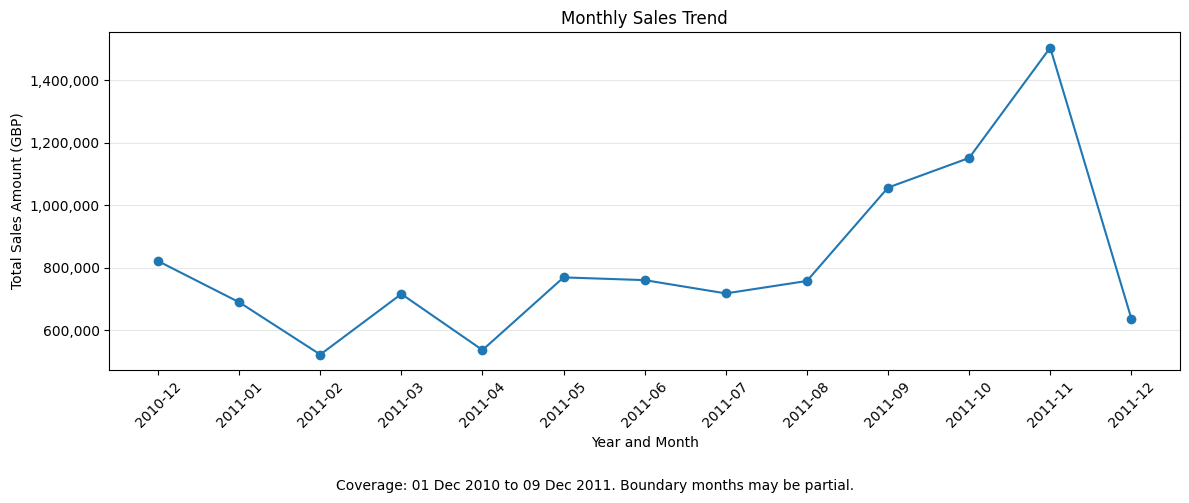

In [3]:
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")
monthly_sales = sales_df.groupby("YearMonth")["SalesAmount"].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Year and Month")
plt.ylabel("Total Sales Amount (GBP)")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.grid(axis="y", alpha=0.3)

coverage_start = sales_df["InvoiceDate"].min().strftime("%d %b %Y")
coverage_end = sales_df["InvoiceDate"].max().strftime("%d %b %Y")
plt.figtext(
    0.5,
    0.01,
    f"Coverage: {coverage_start} to {coverage_end}. Boundary months may be partial.",
    ha="center",
)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(FIGURES_DIR / "monthly_sales.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Country Sales Analysis

**1. Which country has the highest sales?**  
The United Kingdom has the highest sales at £9,001,744.09.

**2. What percentage of total sales comes from that country?**  
The United Kingdom contributes approximately 84.59% of total sales in our filtered sales data.

**3. What business risk could arise from relying heavily on one country?**  
A fall in UK demand could significantly reduce overall sales. Growing sales in other countries could help reduce this risk.

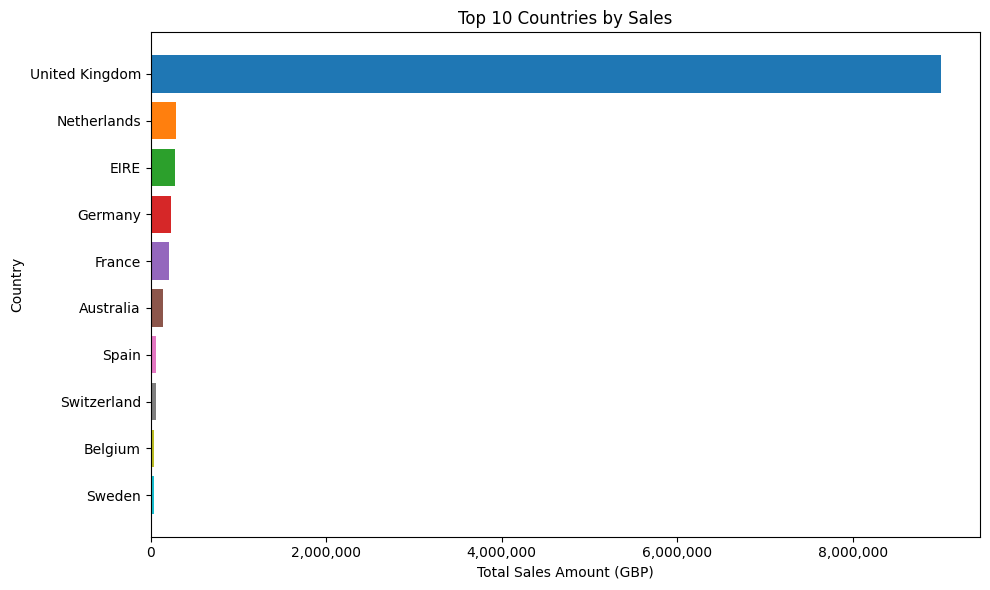

In [4]:
country_sales = sales_df.groupby("Country")["SalesAmount"].sum()
country_sales = country_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(country_sales.index, country_sales.values, color=colors)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.xlabel("Total Sales Amount (GBP)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Sales")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_10_countries.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Product Sales Analysis

**1. Which product has the highest sales amount?**  
StockCode 22423 has the highest sales amount at £174,156.54.

**2. Which product ranks second?**  
StockCode 23843 ranks second with £168,469.60.

**3. Which entries were excluded from this ranking?**  
DOT and POST were excluded because they represent postage charges. M was excluded because its description is “Manual,” which does not identify a specific product.

**4. Does the highest sales amount mean the highest profit?**  
No. We need product cost information to calculate profit.

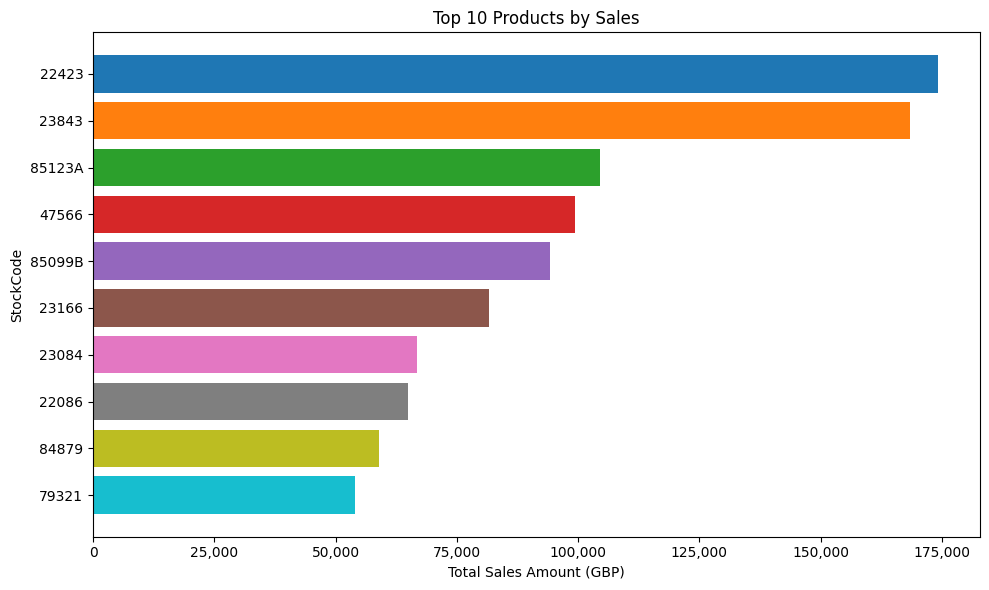

In [5]:
products_df = sales_df[~sales_df["StockCode"].isin(["DOT", "POST", "M"])]
product_sales = products_df.groupby("StockCode")["SalesAmount"].sum()
product_sales = product_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(product_sales.index.astype(str), product_sales.values, color=colors)
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.xlabel("Total Sales Amount (GBP)")
plt.ylabel("StockCode")
plt.title("Top 10 Products by Sales")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Customer Analysis

**1. How many customers purchased only once?**  
1,493 customers purchased only once.

**2. How many customers purchased more than once?**  
2,845 customers purchased more than once.

**3. What percentage of customers purchased more than once?**  
65.58% of customers purchased more than once.

**Note:** These results include only customers with a recorded CustomerID, within the dataset’s date range.

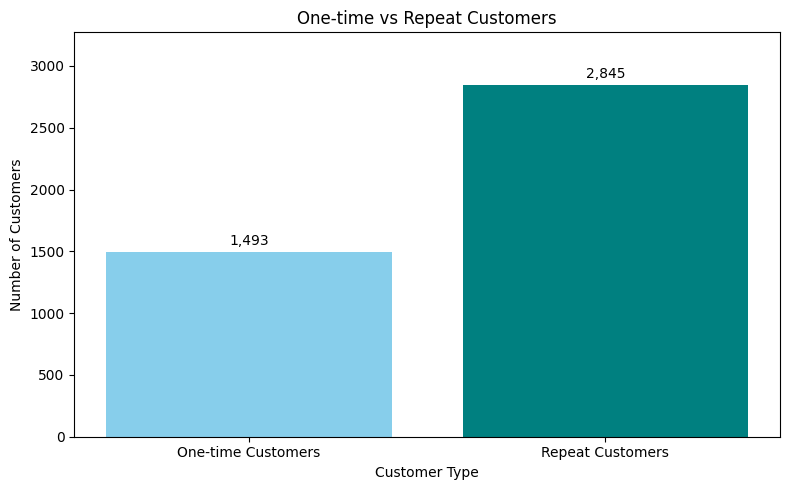

In [6]:
customer_sales = sales_df.dropna(subset=["CustomerID"])
customer_invoices = (
    customer_sales.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="InvoiceCount")
)
one_time_customers = customer_invoices.query("InvoiceCount == 1").shape[0]
repeat_customers = customer_invoices.query("InvoiceCount > 1").shape[0]

customer_types = ["One-time Customers", "Repeat Customers"]
customer_counts = [one_time_customers, repeat_customers]

plt.figure(figsize=(8, 5))
bars = plt.bar(customer_types, customer_counts, color=["skyblue", "teal"])
plt.bar_label(bars, labels=[f"{count:,}" for count in customer_counts], padding=3)
plt.ylim(0, max(customer_counts, default=0) * 1.15 or 1)
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.title("One-time vs Repeat Customers")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "customer_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()